In [ ]:
!nvidia-smi

Sat Oct 10 13:28:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P0             28W /   70W |    1463MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q unsloth

In [ ]:
from unsloth import FastLanguageModel

print("Unsloth installed successfully!")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
Unsloth installed successfully!


In [ ]:
from unsloth import FastLanguageModel
import torch

max_seq_length = 2048

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Qwen2.5-1.5B-Instruct-bnb-4bit",
    max_seq_length=max_seq_length,
    load_in_4bit=True,
)

print("Qwen2.5-1.5B-Instruct loaded successfully!")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.3: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Qwen2.5-1.5B-Instruct loaded successfully!


In [ ]:
from datasets import Dataset

data = [
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Show all customers from Chennai.",
        "output": "SELECT * FROM customers WHERE city = 'Chennai';"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Find all products with a price greater than 1000.",
        "output": "SELECT * FROM products WHERE price > 1000;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Show the names of all employees in the IT department.",
        "output": "SELECT name FROM employees WHERE department = 'IT';"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Count the total number of customers.",
        "output": "SELECT COUNT(*) FROM customers;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Find the five most expensive products.",
        "output": "SELECT * FROM products ORDER BY price DESC LIMIT 5;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Show all orders placed in 2025.",
        "output": "SELECT * FROM orders WHERE YEAR(order_date) = 2025;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Find the average salary of employees.",
        "output": "SELECT AVG(salary) FROM employees;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Show customers who have placed more than 5 orders.",
        "output": "SELECT customer_id, COUNT(*) AS order_count FROM orders GROUP BY customer_id HAVING COUNT(*) > 5;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Find the cheapest product.",
        "output": "SELECT * FROM products ORDER BY price ASC LIMIT 1;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Show the total sales amount for each product.",
        "output": "SELECT product_id, SUM(amount) AS total_sales FROM sales GROUP BY product_id;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Find employees whose salary is above 50000.",
        "output": "SELECT * FROM employees WHERE salary > 50000;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Show the number of orders for each customer.",
        "output": "SELECT customer_id, COUNT(*) AS order_count FROM orders GROUP BY customer_id;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Find all customers whose name starts with A.",
        "output": "SELECT * FROM customers WHERE name LIKE 'A%';"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Show products belonging to the Electronics category.",
        "output": "SELECT * FROM products WHERE category = 'Electronics';"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Find the highest salary among employees.",
        "output": "SELECT MAX(salary) FROM employees;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Show all orders sorted by order date from newest to oldest.",
        "output": "SELECT * FROM orders ORDER BY order_date DESC;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Find customers who live in Tamil Nadu.",
        "output": "SELECT * FROM customers WHERE state = 'Tamil Nadu';"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Calculate the total revenue from all sales.",
        "output": "SELECT SUM(amount) FROM sales;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Show employees ordered by salary from highest to lowest.",
        "output": "SELECT * FROM employees ORDER BY salary DESC;"
    },
    {
        "instruction": "Convert the natural language request into SQL.",
        "input": "Find the total number of products in each category.",
        "output": "SELECT category, COUNT(*) AS product_count FROM products GROUP BY category;"
    }
]

dataset = Dataset.from_list(data)

print("Dataset created successfully!")
print("Number of examples:", len(dataset))

Dataset created successfully!
Number of examples: 20


In [ ]:
def format_chat(example):
    messages = [
        {
            "role": "user",
            "content": f"{example['instruction']}\n\n{example['input']}"
        },
        {
            "role": "assistant",
            "content": example["output"]
        }
    ]

    return {
        "text": tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False
        )
    }


dataset = dataset.map(format_chat)

print(dataset[0]["text"])

Map:   0%|          | 0/20 [00:00<?, ? examples/s]

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Convert the natural language request into SQL.

Show all customers from Chennai.<|im_end|>
<|im_start|>assistant
SELECT * FROM customers WHERE city = 'Chennai';<|im_end|>



In [ ]:
model = FastLanguageModel.get_peft_model(
    model,
    r=8,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj",
    ],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=3407,
)

print("LoRA configured successfully!")

Unsloth 2026.10.3 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


LoRA configured successfully!


In [ ]:
from trl import SFTTrainer, SFTConfig

trainer = SFTTrainer(
        model=model,
            processing_class=tokenizer,
            train_dataset=dataset,
            args=SFTConfig(
                        output_dir="qwen_sql_lora",
                                dataset_text_field="text",
                                max_length=max_seq_length,
                                per_device_train_batch_size=2,
                                gradient_accumulation_steps=4,
                                warmup_steps=5,
                                num_train_epochs=3,
                                learning_rate=2e-4,
                                logging_steps=1,
                                optim="adamw_8bit",
                                weight_decay=0.01,
                                lr_scheduler_type="linear",
                                seed=3407,
                                fp16=True,
                                report_to="none",
                                save_strategy="epoch",
                            ),
        )
print("Trainer configured; examples:", len(dataset))

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/20 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.
Trainer configured; examples: 20


In [ ]:
from unsloth import FastLanguageModel

print("FastLanguageModel imported successfully!")

FastLanguageModel imported successfully!


In [ ]:
training_stats = trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 20 | Num Epochs = 3 | Total steps = 9
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 9,232,384 of 1,552,946,688 (0.59% trained)


Step,Training Loss
1,3.196204
2,3.441848
3,3.279837
4,2.583107
5,2.402323
6,2.080895
7,1.660294
8,1.379517
9,1.251336


Unsloth: Restored added_tokens_decoder metadata in qwen_sql_lora/checkpoint-3/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in qwen_sql_lora/checkpoint-6/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in qwen_sql_lora/checkpoint-9/tokenizer_config.json.


In [ ]:
model.save_pretrained("qwen_sql_lora")
tokenizer.save_pretrained("qwen_sql_lora")
print("LoRA adapter saved.")

Unsloth: Restored added_tokens_decoder metadata in qwen_sql_lora/tokenizer_config.json.


LoRA adapter saved.


In [ ]:
FastLanguageModel.for_inference(model)

messages = [
    {
        "role": "user",
        "content": "Convert the natural language request into SQL.\n\nShow the five most expensive products."
    }
]

inputs = tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_tensors="pt",
).to("cuda")

outputs = model.generate(
    input_ids=inputs,
    max_new_tokens=128,
    do_sample=False,
    use_cache=True,
)

new_tokens = outputs[0][inputs.shape[-1]:]
print(tokenizer.decode(new_tokens, skip_special_tokens=True))

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


SELECT * FROM products ORDER BY price DESC LIMIT 5;


In [ ]:
test_questions = [
    "How many products cost more than 500?",
    "Show employee names in the HR department.",
    "Count all orders placed in 2024."
]

for question in test_questions:
    messages = [{
        "role": "user",
        "content": f"Convert the natural language request into SQL.\n\n{question}"
    }]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
    ).to("cuda")

    outputs = model.generate(
        input_ids=inputs,
        max_new_tokens=128,
        do_sample=False,
        use_cache=True,
    )

    answer = tokenizer.decode(
        outputs[0][inputs.shape[-1]:],
        skip_special_tokens=True,
    )
    print(f"Request: {question}\nSQL: {answer}\n")

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Request: How many products cost more than 500?
SQL: SELECT COUNT(*) FROM products WHERE price > 500;



Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Request: Show employee names in the HR department.
SQL: SELECT name FROM employees WHERE department = 'HR'

Request: Count all orders placed in 2024.
SQL: SELECT COUNT(*) FROM orders WHERE YEAR(order_date) = 2024;



In [ ]:
from google.colab import drive
drive.mount("/content/drive")

save_path = "/content/drive/MyDrive/qwen_sql_lora"

model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print("Adapter saved to:", save_path)

Mounted at /content/drive


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/qwen_sql_lora/tokenizer_config.json.


Adapter saved to: /content/drive/MyDrive/qwen_sql_lora


In [16]:
import os

print("Files in current directory:")
for item in os.listdir("/content"):
    print(item)

Files in current directory:
.config
qwen_sql_lora
huggingface_tokenizers_cache
unsloth_compiled_cache
drive
sample_data


In [17]:
import os

folder = "/content/qwen_sql_lora"

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  {file}")

qwen_sql_lora/
  adapter_config.json
  chat_template.jinja
  tokenizer.json
  tokenizer_config.json
  adapter_model.safetensors
  README.md
  checkpoint-9/
    scheduler.pt
    trainer_state.json
    adapter_config.json
    chat_template.jinja
    tokenizer.json
    optimizer.pt
    tokenizer_config.json
    adapter_model.safetensors
    training_args.bin
    scaler.pt
    rng_state.pth
    README.md
  checkpoint-6/
    scheduler.pt
    trainer_state.json
    adapter_config.json
    chat_template.jinja
    tokenizer.json
    optimizer.pt
    tokenizer_config.json
    adapter_model.safetensors
    training_args.bin
    scaler.pt
    rng_state.pth
    README.md
  checkpoint-3/
    scheduler.pt
    trainer_state.json
    adapter_config.json
    chat_template.jinja
    tokenizer.json
    optimizer.pt
    tokenizer_config.json
    adapter_model.safetensors
    training_args.bin
    scaler.pt
    rng_state.pth
    README.md


In [18]:
import os
import json

folder = "/content/qwen_sql_lora"

for checkpoint in ["checkpoint-3", "checkpoint-6", "checkpoint-9"]:
    path = os.path.join(folder, checkpoint, "trainer_state.json")

    if os.path.exists(path):
        with open(path, "r") as f:
            state = json.load(f)

        print(f"\n{checkpoint}")
        print("Global step:", state.get("global_step"))

        history = state.get("log_history", [])
        for entry in history:
            if "loss" in entry:
                print(
                    "Step:", entry.get("step"),
                    "| Loss:", entry["loss"]
                )


checkpoint-3
Global step: 3
Step: 1 | Loss: 3.1962037086486816
Step: 2 | Loss: 3.441847801208496
Step: 3 | Loss: 3.279836654663086

checkpoint-6
Global step: 6
Step: 1 | Loss: 3.1962037086486816
Step: 2 | Loss: 3.441847801208496
Step: 3 | Loss: 3.279836654663086
Step: 4 | Loss: 2.5831074714660645
Step: 5 | Loss: 2.402323007583618
Step: 6 | Loss: 2.08089542388916

checkpoint-9
Global step: 9
Step: 1 | Loss: 3.1962037086486816
Step: 2 | Loss: 3.441847801208496
Step: 3 | Loss: 3.279836654663086
Step: 4 | Loss: 2.5831074714660645
Step: 5 | Loss: 2.402323007583618
Step: 6 | Loss: 2.08089542388916
Step: 7 | Loss: 1.660293698310852
Step: 8 | Loss: 1.3795170783996582
Step: 9 | Loss: 1.251335620880127


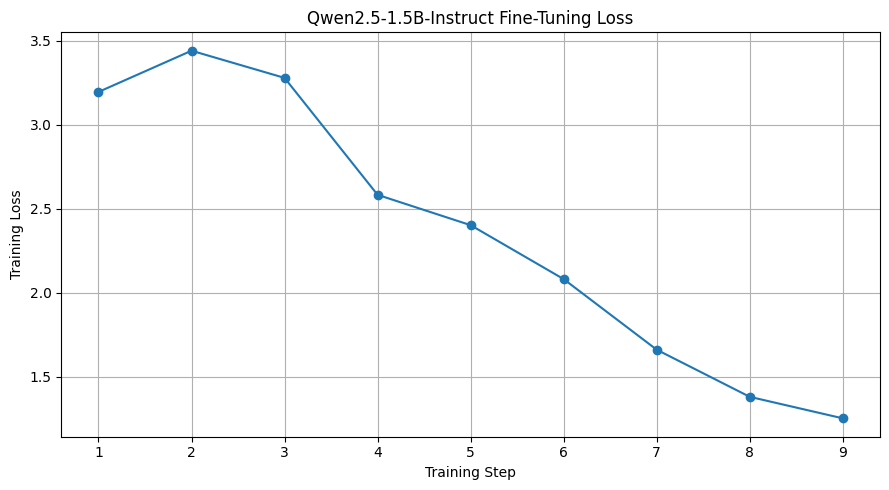

Training loss graph saved to: /content/training_loss.png


In [19]:
import json
import matplotlib.pyplot as plt

path = "/content/qwen_sql_lora/checkpoint-9/trainer_state.json"

with open(path, "r") as f:
    state = json.load(f)

steps = []
losses = []

for entry in state["log_history"]:
    if "loss" in entry:
        steps.append(entry["step"])
        losses.append(entry["loss"])

plt.figure(figsize=(9, 5))
plt.plot(steps, losses, marker="o")
plt.title("Qwen2.5-1.5B-Instruct Fine-Tuning Loss")
plt.xlabel("Training Step")
plt.ylabel("Training Loss")
plt.grid(True)
plt.tight_layout()

output_path = "/content/training_loss.png"
plt.savefig(output_path, dpi=300)
plt.show()

print("Training loss graph saved to:", output_path)

In [20]:
from google.colab import files

files.download("/content/training_loss.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import torch
import pandas as pd
from unsloth import FastLanguageModel

# Load the trained LoRA adapter
model_path = "/content/qwen_sql_lora"

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=model_path,
    max_seq_length=2048,
    load_in_4bit=True,
)

FastLanguageModel.for_inference(model)

print("Fine-tuned model loaded successfully!")

==((====))==  Unsloth 2026.10.3: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Fine-tuned model loaded successfully!


In [22]:
import torch
import pandas as pd
from unsloth import FastLanguageModel

# Test questions
test_questions = [
    "Show all customers from Chennai.",
    "Find the cheapest product.",
    "Count the total number of customers.",
    "Find employees whose salary is above 50000.",
    "Show products belonging to the Electronics category."
]

def generate_sql(model, tokenizer, question):
    messages = [
        {
            "role": "user",
            "content": (
                "Convert the natural language request into SQL.\n\n"
                + question
            )
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to("cuda")

    with torch.no_grad():
        outputs = model.generate(
            inputs,
            max_new_tokens=128,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs.shape[-1]:]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()


# Generate fine-tuned model predictions
fine_tuned_results = []

for question in test_questions:
    answer = generate_sql(model, tokenizer, question)
    fine_tuned_results.append(answer)

    print("\nQuestion:", question)
    print("Fine-tuned SQL:", answer)

print("\nFine-tuned model testing completed!")

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Question: Show all customers from Chennai.
Fine-tuned SQL: SELECT * FROM customers WHERE city = 'Chennai';


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Question: Find the cheapest product.
Fine-tuned SQL: SELECT * FROM products ORDER BY price ASC LIMIT 1;


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Question: Count the total number of customers.
Fine-tuned SQL: SELECT COUNT(*) FROM customers;


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Question: Find employees whose salary is above 50000.
Fine-tuned SQL: SELECT * FROM Employees WHERE Salary > 50000;

Question: Show products belonging to the Electronics category.
Fine-tuned SQL: SELECT * FROM Products WHERE Category = 'Electronics';

Fine-tuned model testing completed!


In [24]:
# Save fine-tuned predictions
fine_tuned_results = [
    "SELECT * FROM customers WHERE city = 'Chennai';",
    "SELECT * FROM products ORDER BY price ASC LIMIT 1;",
    "SELECT COUNT(*) FROM customers;",
    "SELECT * FROM Employees WHERE Salary > 50000;",
    "SELECT * FROM Products WHERE Category = 'Electronics';"
]

test_questions = [
    "Show all customers from Chennai.",
    "Find the cheapest product.",
    "Count the total number of customers.",
    "Find employees whose salary is above 50000.",
    "Show products belonging to the Electronics category."
]

print("Saved", len(fine_tuned_results), "fine-tuned predictions.")

Saved 5 fine-tuned predictions.


In [25]:
from unsloth import FastLanguageModel

base_model, base_tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Qwen2.5-1.5B-Instruct-bnb-4bit",
    max_seq_length=2048,
    load_in_4bit=True,
)

FastLanguageModel.for_inference(base_model)

print("Base model loaded successfully!")

==((====))==  Unsloth 2026.10.3: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Base model loaded successfully!


In [26]:
import torch

def generate_base_sql(question):
    messages = [
        {
            "role": "user",
            "content": (
                "Convert the natural language request into SQL.\n\n"
                + question
            )
        }
    ]

    inputs = base_tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to("cuda")

    with torch.no_grad():
        outputs = base_model.generate(
            inputs,
            max_new_tokens=128,
            do_sample=False,
            pad_token_id=base_tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs.shape[-1]:]

    return base_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()


base_results = []

for question in test_questions:
    answer = generate_base_sql(question)
    base_results.append(answer)

    print("\nQuestion:", question)
    print("Base Model SQL:", answer)

print("\nBase model testing completed!")

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Question: Show all customers from Chennai.
Base Model SQL: ```sql
SELECT * FROM Customers WHERE City = 'Chennai';
```


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Question: Find the cheapest product.
Base Model SQL: To convert the natural language request "Find the cheapest product" into an SQL query, you would typically need to know the specific database schema and structure of your data. However, I can provide a general example based on common database structures:

Assuming you have a table named `products` with columns like `product_id`, `price`, and possibly other relevant information, here is how you might write an SQL query to find the cheapest product:

```sql
SELECT MIN(price) AS lowest_price, product_id
FROM products
GROUP BY product_id;
```

This query calculates the minimum price for each unique product ID in the `products`


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Question: Count the total number of customers.
Base Model SQL: ```sql
SELECT COUNT(*) AS total_customers
FROM customers;
```


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Question: Find employees whose salary is above 50000.
Base Model SQL: ```sql
SELECT * FROM Employees
WHERE Salary > 50000;
```

Question: Show products belonging to the Electronics category.
Base Model SQL: ```sql
SELECT * FROM Products
WHERE Category = 'Electronics';
```

Base model testing completed!


In [27]:
import pandas as pd

comparison_data = {
    "Question": test_questions,
    "Base_Model_Output": base_results,
    "Fine_Tuned_Model_Output": fine_tuned_results
}

df = pd.DataFrame(comparison_data)

df.to_csv(
    "/content/base_vs_finetuned.csv",
    index=False
)

print("Comparison CSV created successfully!")
display(df)

Comparison CSV created successfully!


,Question,Base_Model_Output,Fine_Tuned_Model_Output
0,Show all customers from Chennai.,```sql\nSELECT * FROM Customers WHERE City = '...,SELECT * FROM customers WHERE city = 'Chennai';
1,Find the cheapest product.,"To convert the natural language request ""Find ...",SELECT * FROM products ORDER BY price ASC LIMI...
2,Count the total number of customers.,```sql\nSELECT COUNT(*) AS total_customers\nFR...,SELECT COUNT(*) FROM customers;
3,Find employees whose salary is above 50000.,```sql\nSELECT * FROM Employees\nWHERE Salary ...,SELECT * FROM Employees WHERE Salary > 50000;
4,Show products belonging to the Electronics cat...,```sql\nSELECT * FROM Products\r\nWHERE Catego...,SELECT * FROM Products WHERE Category = 'Elect...


In [29]:
import re
import pandas as pd

expected_sql = [
    "SELECT * FROM customers WHERE city = 'Chennai';",
    "SELECT * FROM products ORDER BY price ASC LIMIT 1;",
    "SELECT COUNT(*) FROM customers;",
    "SELECT * FROM employees WHERE salary > 50000;",
    "SELECT * FROM products WHERE category = 'Electronics';"
]

def normalize_sql(sql):
    sql = re.sub(r"```sql|```", "", str(sql), flags=re.IGNORECASE)
    sql = re.sub(r"\s+", " ", sql).strip().rstrip(";")
    return sql.lower()

base_correct = []
fine_tuned_correct = []

for i in range(len(test_questions)):
    expected = normalize_sql(expected_sql[i])

    base_correct.append(
        normalize_sql(base_results[i]) == expected
    )

    fine_tuned_correct.append(
        normalize_sql(fine_tuned_results[i]) == expected
    )

results = pd.DataFrame({
    "Question": test_questions,
    "Expected_SQL": expected_sql,
    "Base_Correct": base_correct,
    "Fine_Tuned_Correct": fine_tuned_correct
})

display(results)

print("\nBASE MODEL")
print(f"Exact match: {sum(base_correct)}/{len(base_correct)}")

print("\nFINE-TUNED MODEL")
print(f"Exact match: {sum(fine_tuned_correct)}/{len(fine_tuned_correct)}")

results.to_csv("/content/sql_evaluation_results.csv", index=False)

print("\nSaved: /content/sql_evaluation_results.csv")

,Question,Expected_SQL,Base_Correct,Fine_Tuned_Correct
0,Show all customers from Chennai.,SELECT * FROM customers WHERE city = 'Chennai';,True,True
1,Find the cheapest product.,SELECT * FROM products ORDER BY price ASC LIMI...,False,True
2,Count the total number of customers.,SELECT COUNT(*) FROM customers;,False,True
3,Find employees whose salary is above 50000.,SELECT * FROM employees WHERE salary > 50000;,True,True
4,Show products belonging to the Electronics cat...,SELECT * FROM products WHERE category = 'Elect...,True,True



BASE MODEL
Exact match: 3/5

FINE-TUNED MODEL
Exact match: 5/5

Saved: /content/sql_evaluation_results.csv


In [30]:
import os
import shutil

submission_dir = "/content/Task_02_Submission"

os.makedirs(submission_dir, exist_ok=True)

# Copy training loss graph
shutil.copy(
    "/content/training_loss.png",
    f"{submission_dir}/training_loss.png"
)

# Copy base vs fine-tuned comparison
shutil.copy(
    "/content/base_vs_finetuned.csv",
    f"{submission_dir}/base_vs_finetuned.csv"
)

# Copy SQL evaluation results
shutil.copy(
    "/content/sql_evaluation_results.csv",
    f"{submission_dir}/sql_evaluation_results.csv"
)

# Copy the trained LoRA adapter
shutil.copytree(
    "/content/qwen_sql_lora",
    f"{submission_dir}/qwen_sql_lora",
    dirs_exist_ok=True
)

print("Submission files prepared successfully!")

for item in os.listdir(submission_dir):
    print(item)

Submission files prepared successfully!
qwen_sql_lora
base_vs_finetuned.csv
sql_evaluation_results.csv
training_loss.png


## Task 02: QLoRA Fine-Tuning — Natural Language to SQL

- **Model:** Qwen2.5-1.5B-Instruct, 4-bit
- **Training data:** 20 examples
- **LoRA:** Rank 8, alpha 16
- **Training:** 3 epochs, 9 steps
- **Loss:** Step 1-la 3.196; final step-la 1.251
- **Adapter:** `MyDrive/qwen_sql_lora`

### Test results

- “Show the five most expensive products”  
  `SELECT * FROM products ORDER BY price DESC LIMIT 5;`

- “How many products cost more than 500?”  
  `SELECT COUNT(*) FROM products WHERE price > 500;`

- “Show employee names in the HR department”  
  `SELECT name FROM employees WHERE department = 'HR'`

- “Count all orders placed in 2024”  
  `SELECT COUNT(*) FROM orders WHERE YEAR(order_date) = 2024;`

The model generated SQL for these test prompts. The dataset is small, so more testing is needed to evaluate performance on new schemas and requests.